In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
df = pd.read_csv("Student_Performance.csv")

print("Shape:", df.shape)
print(df.head())
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum())

Shape: (10000, 6)
   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  

Column types:
Hours Studied                         int64
Previous Scores                       int64
Extracurricular Activities           object
Sleep Hours                   

In [3]:
df["Extracurricular Activities"] = df["Extracurricular Activities"].map({"Yes": 1, "No": 0})
df = df.dropna()

In [4]:
target = "Performance Index"
print("\nCorrelation with Performance Index:")
print(df.corr()[target].sort_values(ascending=False))


Correlation with Performance Index:
Performance Index                   1.000000
Previous Scores                     0.915189
Hours Studied                       0.373730
Sleep Hours                         0.048106
Sample Question Papers Practiced    0.043268
Extracurricular Activities          0.024525
Name: Performance Index, dtype: float64


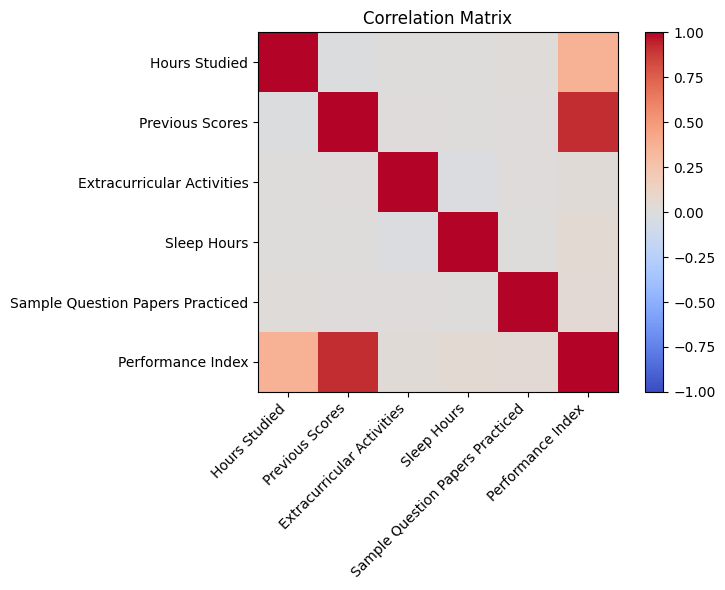

In [5]:
plt.figure(figsize=(8, 6))
plt.imshow(df.corr(), cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(df.columns)), df.columns, rotation=45, ha="right")
plt.yticks(range(len(df.columns)), df.columns)
plt.colorbar()
plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig("correlation_matrix.png", dpi=120)
plt.show()

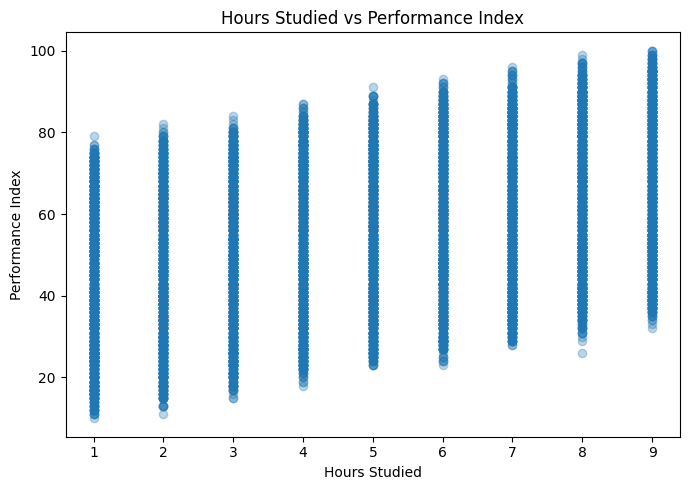

In [6]:
plt.figure(figsize=(7, 5))
plt.scatter(df["Hours Studied"], df[target], alpha=0.3)
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.title("Hours Studied vs Performance Index")
plt.tight_layout()
plt.savefig("hours_vs_performance.png", dpi=120)
plt.show()

In [7]:
x = df.drop(columns=[target])
y = df[target]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print("\nTrain size:", x_train.shape[0], "| Test size:", x_test.shape[0])


Train size: 8000 | Test size: 2000


In [8]:
regressor = LinearRegression()
regressor.fit(x_train, y_train)

LinearRegression()

In [9]:
print("\nIntercept:", round(regressor.intercept_, 4))
coef_table = pd.DataFrame({
    "Feature": x.columns,
    "Coefficient": regressor.coef_.round(4)
})
print(coef_table)


Intercept: -33.9219
                            Feature  Coefficient
0                     Hours Studied       2.8525
1                   Previous Scores       1.0170
2        Extracurricular Activities       0.6086
3                       Sleep Hours       0.4769
4  Sample Question Papers Practiced       0.1918


In [10]:
y_pred = regressor.predict(x_test)
comparison = pd.DataFrame({"Actual": y_test.values,"Predicted": y_pred.round(2)})
print("\nActual vs Predicted (first 10):")
print(comparison.head(10))


Actual vs Predicted (first 10):
   Actual  Predicted
0    51.0      54.71
1    20.0      22.62
2    46.0      47.90
3    28.0      31.29
4    41.0      43.00
5    59.0      59.07
6    48.0      45.90
7    87.0      86.46
8    37.0      37.70
9    73.0      72.06


In [11]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\n--- Model Performance ---")
print("Train R2 :", round(regressor.score(x_train, y_train), 4))
print("Test  R2 :", round(r2, 4))
print("MAE      :", round(mae, 4))
print("RMSE     :", round(rmse, 4))


--- Model Performance ---
Train R2 : 0.9887
Test  R2 : 0.989
MAE      : 1.6111
RMSE     : 2.0206


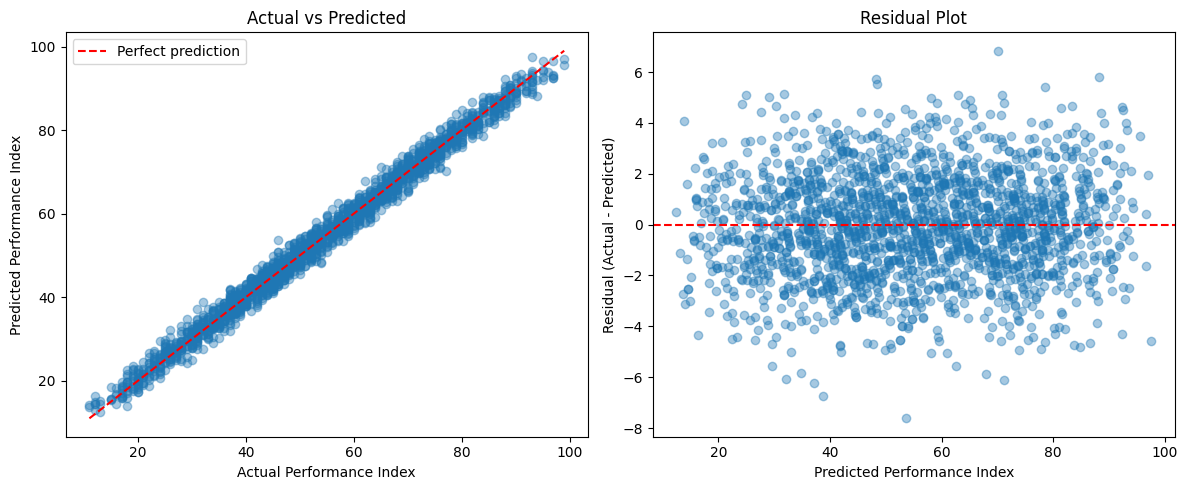

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Actual vs predicted
ax[0].scatter(y_test, y_pred, alpha=0.4)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[0].plot(lims, lims, "r--", label="Perfect prediction")
ax[0].set_xlabel("Actual Performance Index")
ax[0].set_ylabel("Predicted Performance Index")
ax[0].set_title("Actual vs Predicted")
ax[0].legend()

# Residuals
residuals = y_test - y_pred
ax[1].scatter(y_pred, residuals, alpha=0.4)
ax[1].axhline(0, color="r", linestyle="--")
ax[1].set_xlabel("Predicted Performance Index")
ax[1].set_ylabel("Residual (Actual - Predicted)")
ax[1].set_title("Residual Plot")

plt.tight_layout()
plt.savefig("regression_results.png", dpi=120)
plt.show()

In [13]:
new_student = pd.DataFrame({
    "Hours Studied": [7],
    "Previous Scores": [85],
    "Extracurricular Activities": [1],          # 1 = Yes, 0 = No
    "Sleep Hours": [7],
    "Sample Question Papers Practiced": [5],
})
prediction = regressor.predict(new_student)
print(f"\nPredicted Performance Index for the new student: {prediction[0]:.2f}")


Predicted Performance Index for the new student: 77.40
